# Manifold Benchmark v2: geometry-aware baselines and rough initial conditions

Follow-up to `benchmark_manifolds.ipynb` (same domains, PDEs, training
protocol), addressing its two main caveats:

1. **Geometry-aware baselines.** The 1D baselines there only saw a vertex
   ordering. Two baselines that see the real geometry are added:

   | model | domain | how it sees the surface |
   |---|---|---|
   | **SFNO** (`ref_models/sfno.py`) | Sphere | FNO with the FFT replaced by the spherical harmonic transform on a 32 x 64 Gauss-Legendre grid, Driscoll-Healy (per-degree) weights |
   | **FNO2d** (`ref_models/fno2d.py`) | Torus | reference 2D FNO on the torus's own periodic (major x minor angle) grid - the mesh vertices *are* that grid, so no interpolation |

2. **Initial conditions outside our basis.** Previously the ICs were
   combinations of the lowest 15 Laplace-Beltrami modes - exactly
   representable by our model. `IC_TYPE = "noise"` instead uses white noise
   on the vertices smoothed by a short heat flow (as in `main.ipynb`), which
   puts ~20% of each field's norm *above* our 96 retained modes.

**Configuration by environment variable** (so one notebook covers every job):

| variable | default | meaning |
|---|---|---|
| `IC_TYPE` | `noise` | `noise` (rough ICs) or `lowmodes` (reproduces the previous run's data) |
| `MODELS` | all | comma list from `Ours,CNO,FNO,LNO,SFNO,FNO2d` |
| `OURS_MICRO_BATCH` | 16 | gradient-accumulation chunk for our O(V^2) model |
| `BENCHMARK_SMOKE` | unset | `1` = tiny data, 2 epochs |

In [1]:
import os
import json
import time
import numpy as np
import scipy.sparse as sp
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import trimesh
from scipy.sparse.linalg import eigsh, expm_multiply

from equations import (
    MeshDomain,
    DiffusionEquation,
    ReactionDiffusion,
    BeamEquation,
)
from model import HeatKernel, IntegralOperator, IntegralOperatorModel
from ref_models.cno import CNOOperator
from ref_models.fno import FNOOperator
from ref_models.lno import LNOOperator
from ref_models.sfno import SphereSFNOOperator
from ref_models.fno2d import TorusFNO2dOperator

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## Configuration

In [2]:
SEED = 0
N_TOTAL = 128           # samples per (domain, system)
N_TRAIN = 96
N_EPOCHS = 1000
BATCH_SIZE = 32
LEARNING_RATE = 1e-3

IC_TYPE = os.environ.get("IC_TYPE", "noise")
if IC_TYPE not in ("noise", "lowmodes"):
    raise ValueError(f"IC_TYPE must be 'noise' or 'lowmodes', got {IC_TYPE!r}")

ALL_MODELS = ["Ours", "CNO", "FNO", "LNO", "SFNO", "FNO2d"]
MODELS = [m.strip() for m in os.environ.get("MODELS", ",".join(ALL_MODELS)).split(",") if m.strip()]
unknown = set(MODELS) - set(ALL_MODELS)
if unknown:
    raise ValueError(f"unknown models {sorted(unknown)}; choose from {ALL_MODELS}")

# Meshes (~640 vertices each) - identical to benchmark_manifolds.ipynb
SPHERE_SUBDIVISIONS = 3             # icosphere: 642 vertices
TORUS_MAJOR_RADIUS = 1.0
TORUS_MINOR_RADIUS = 0.3
TORUS_MAJOR_SECTIONS = 40           # 40 x 16 = 640 vertices
TORUS_MINOR_SECTIONS = 16

# Vertex order seen by the 1D baselines (see benchmark_manifolds.ipynb)
VERTEX_ORDER = "raster"

# Initial conditions
N_IC_MODES = 15                     # "lowmodes": lowest LB modes, constant excluded
NOISE_SMOOTHING_TIME = 0.02         # "noise": exp(s * Laplacian) applied to white noise;
                                    # s = 0.02 leaves ~20% of the norm above our 96 modes

# Our model (as before)
N_MODES = 96
N_DIFFUSION_TIMES = 12
HIDDEN_CHANNELS = 32
LATENT_CHANNELS = 8
N_OPERATOR_LAYERS = 4
OURS_MICRO_BATCH = int(os.environ.get("OURS_MICRO_BATCH", "16"))

# Geometry-aware baselines
SFNO_NLAT = 32                      # 32 x 64 Gauss-Legendre grid, degrees up to 31
SFNO_MODES = 16                     # spectral weights for degrees l <= 16 (cf. FNO modes=16)
SFNO_WIDTH = 64                     # as the 1D FNO baseline
FNO2D_MODES = 12                    # reference fourier_2d.py defaults
FNO2D_WIDTH = 32

ADD_COORDINATE_CHANNELS = True

# Physical parameters - identical to benchmark_manifolds.ipynb
PDE_SETTINGS = {
    "Sphere": dict(D=0.1, k=0.5, T=1.0, EI=0.04, rho_A=1.0, T_beam=1.0),
    "Torus":  dict(D=0.1, k=0.5, T=1.0, EI=0.04, rho_A=1.0, T_beam=1.0),
}

if os.environ.get("BENCHMARK_SMOKE") == "1":
    N_TOTAL, N_TRAIN, N_EPOCHS, BATCH_SIZE = 12, 8, 2, 4
    print("SMOKE TEST MODE")

print(f"IC_TYPE = {IC_TYPE}   MODELS = {MODELS}   OURS_MICRO_BATCH = {OURS_MICRO_BATCH}")

IC_TYPE = lowmodes   MODELS = ['Ours', 'CNO', 'FNO', 'LNO', 'SFNO', 'FNO2d']   OURS_MICRO_BATCH = 16


## Domains (unchanged)

In [3]:
def reorder_mesh(vertices, faces, order):
    inverse = np.empty_like(order)
    inverse[order] = np.arange(len(order))
    return vertices[order], inverse[faces]


def snake_order(band, angle):
    key = np.where(band % 2 == 0, angle, -angle)
    return np.lexsort((key, band))


def sphere_raster(vertices):
    polar = np.arccos(np.clip(vertices[:, 2] / np.linalg.norm(vertices, axis=1), -1, 1))
    azimuth = np.arctan2(vertices[:, 1], vertices[:, 0])
    n_bands = int(round(np.sqrt(len(vertices))))
    band = np.minimum((polar / np.pi * n_bands).astype(int), n_bands - 1)
    return snake_order(band, azimuth)


def torus_raster(vertices, n_major):
    major = np.mod(np.arctan2(vertices[:, 1], vertices[:, 0]), 2 * np.pi)
    rho = np.hypot(vertices[:, 0], vertices[:, 1])
    minor = np.arctan2(vertices[:, 2], rho - TORUS_MAJOR_RADIUS)
    band = np.round(major / (2 * np.pi) * n_major).astype(int) % n_major
    return snake_order(band, minor)


def build_domain(name):
    if name == "Sphere":
        mesh = trimesh.creation.icosphere(subdivisions=SPHERE_SUBDIVISIONS, radius=1.0)
        order_fn = sphere_raster
    else:
        mesh = trimesh.creation.torus(
            major_radius=TORUS_MAJOR_RADIUS,
            minor_radius=TORUS_MINOR_RADIUS,
            major_sections=TORUS_MAJOR_SECTIONS,
            minor_sections=TORUS_MINOR_SECTIONS,
        )
        order_fn = lambda v: torus_raster(v, TORUS_MAJOR_SECTIONS)

    vertices = np.asarray(mesh.vertices, dtype=float)
    faces = np.asarray(mesh.faces)

    if VERTEX_ORDER == "raster":
        vertices, faces = reorder_mesh(vertices, faces, order_fn(vertices))

    return MeshDomain(vertices, faces)


DOMAIN_NAMES = ["Sphere", "Torus"]
domains = {name: build_domain(name) for name in DOMAIN_NAMES}

for name, dom in domains.items():
    print(f"{name:7s} vertices {dom.n_points:4d}  faces {len(dom.faces):5d}  "
          f"area {dom.mass_diagonal.sum():.3f}")

Sphere  vertices  642  faces  1280  area 12.506
Torus   vertices  640  faces  1280  area 11.737


## Laplace-Beltrami eigenpairs (unchanged)

In [4]:
def make_mesh_eigenbasis(domain, n_modes=N_MODES):
    mass = domain.mass_diagonal.astype(np.float64)
    M_inv_sqrt = sp.diags(1.0 / np.sqrt(mass))
    L_symmetric = (M_inv_sqrt @ domain.stiffness @ M_inv_sqrt).tocsc()

    values, vectors = eigsh(L_symmetric, k=n_modes, sigma=-1e-6, which="LM")
    order = np.argsort(values)
    values = np.maximum(values[order], 0.0)
    vectors = np.asarray(M_inv_sqrt @ vectors[:, order])

    return values, vectors, mass


def make_diffusion_times(eigenvalues, n=N_DIFFUSION_TIMES):
    first_nonzero = eigenvalues[eigenvalues > 1e-8][0]
    return list(
        np.logspace(np.log10(1.0 / eigenvalues[-1]),
                    np.log10(3.0 / first_nonzero), n)
    )


bases = {}
for name, dom in domains.items():
    values, vectors, mass = make_mesh_eigenbasis(dom)
    bases[name] = (values, vectors, mass)
    orthogonality_error = np.linalg.norm(
        vectors.T @ (mass[:, None] * vectors) - np.eye(N_MODES)
    )
    print(f"{name}: first eigenvalues {np.round(values[:10], 3)}  "
          f"lambda_max {values[-1]:.1f}  M-orthogonality error {orthogonality_error:.1e}")

Sphere: first eigenvalues [ 0.     2.     2.     2.     5.966  5.966  5.966  5.966  5.966 11.827]  lambda_max 79.5  M-orthogonality error 1.7e-14
Torus: first eigenvalues [ 0.     1.032  1.032  3.903  3.903  8.133  8.133 11.063 11.564 12.121]  lambda_max 91.7  M-orthogonality error 1.7e-14


## Data generation

- `lowmodes`: random combinations of LB modes 1..15, max |u| = 1 - the same
  code and random stream as `benchmark_manifolds.ipynb`.
- `noise`: white noise on the vertices, smoothed by `exp(s * Laplacian)`
  with `s = NOISE_SMOOTHING_TIME`, mass-weighted mean removed, max |u| = 1.

The diagnostics printed after generation say how hard each task is:

- **outside 96 modes**: the part of `u(0)` / `u(T)` our model's basis cannot
  represent (relative, mass-weighted). Our output lies in the span of these 96
  modes, so the `u(T)` number is a hard error floor for our model.
- **SFNO floor** (sphere): error of mapping `u(T)` vertex -> SFNO grid ->
  vertex with no network in between; SFNO cannot go below it.

In [5]:
def random_surface_field(rng, domain_name):
    domain = domains[domain_name]
    _, eigenvectors, mass = bases[domain_name]

    if IC_TYPE == "lowmodes":
        coefficients = rng.normal(size=N_IC_MODES)
        field = eigenvectors[:, 1:N_IC_MODES + 1] @ coefficients
    else:
        noise = rng.normal(size=domain.n_points)
        field = expm_multiply(NOISE_SMOOTHING_TIME * domain.laplacian, noise)
        field = field - (mass @ field) / mass.sum()

    return field / np.abs(field).max()


def make_pde_dataset(domain_name, equation_factory, T, seed=SEED):
    rng = np.random.default_rng(seed)
    u0_list, uT_list = [], []

    for _ in range(N_TOTAL):
        y0 = random_surface_field(rng, domain_name)

        equation = equation_factory()
        equation.set_initial_condition(y0=y0)
        solution = equation.solve([0.0, T], t_eval=[0.0, T])

        u0_list.append(solution.y[:, 0])
        uT_list.append(solution.y[:, -1])

    u0 = torch.tensor(np.array(u0_list), dtype=torch.float32).unsqueeze(-1)
    uT = torch.tensor(np.array(uT_list), dtype=torch.float32).unsqueeze(-1)
    return u0, uT


def make_beam_dataset(domain_name, EI, rho_A, T, seed=SEED):
    rng = np.random.default_rng(seed)
    domain = domains[domain_name]
    n = domain.n_points
    u0_list, uT_list = [], []

    for _ in range(N_TOTAL):
        w0 = random_surface_field(rng, domain_name)

        equation = BeamEquation(domain, EI=EI, rho_A=rho_A)
        equation.set_initial_condition(w0=w0, wdot0=np.zeros_like(w0))
        solution = equation.solve([0.0, T], t_eval=[0.0, T])

        u0_list.append(solution.y[:n, 0])
        uT_list.append(solution.y[:n, -1])

    u0 = torch.tensor(np.array(u0_list), dtype=torch.float32).unsqueeze(-1)
    uT = torch.tensor(np.array(uT_list), dtype=torch.float32).unsqueeze(-1)
    return u0, uT


def outside_basis(U, domain_name):
    # Relative mass-weighted norm of the part of U outside our N_MODES modes
    _, Phi, mass = bases[domain_name]
    U = U[..., 0].numpy().T.astype(np.float64)                 # [V, N]
    projection = Phi @ (Phi.T @ (mass[:, None] * U))
    residual = (mass[:, None] * (U - projection) ** 2).sum()
    return np.sqrt(residual / (mass[:, None] * U ** 2).sum())

In [6]:
datasets = {}
t0 = time.time()

for domain_name in DOMAIN_NAMES:
    dom = domains[domain_name]
    p = PDE_SETTINGS[domain_name]

    datasets[(domain_name, "Diffusion")] = make_pde_dataset(
        domain_name, lambda: DiffusionEquation(dom, D=p["D"]), T=p["T"]
    )
    datasets[(domain_name, "Reaction-Diffusion")] = make_pde_dataset(
        domain_name, lambda: ReactionDiffusion(dom, D=p["D"], k=p["k"]), T=p["T"]
    )
    datasets[(domain_name, "Beam")] = make_beam_dataset(
        domain_name, EI=p["EI"], rho_A=p["rho_A"], T=p["T_beam"]
    )

print(f"data generated in {time.time() - t0:.0f}s  (IC_TYPE = {IC_TYPE})")

sfno_probe = SphereSFNOOperator(domains["Sphere"].points, domains["Sphere"].faces)
data_stats = {}

for (domain_name, system), (X, Y) in datasets.items():
    change = (torch.norm(Y - X) / torch.norm(X)).item()
    stats = {
        "change": change,
        "u0_outside_basis": outside_basis(X, domain_name),
        "uT_outside_basis": outside_basis(Y, domain_name),
    }
    if domain_name == "Sphere":
        with torch.no_grad():
            stats["sfno_floor"] = (
                (sfno_probe.round_trip(Y) - Y).norm() / Y.norm()
            ).item()
    data_stats[f"{domain_name}/{system}"] = stats

    print(f"{domain_name:7s} {system:20s} ||u(T)-u(0)||/||u(0)|| {change:.3f}  "
          f"outside 96 modes: u0 {stats['u0_outside_basis']:.3f}  "
          f"u(T) {stats['uT_outside_basis']:.4f}"
          + (f"  SFNO floor {stats['sfno_floor']:.4f}" if "sfno_floor" in stats else "")
          + f"  finite: {torch.isfinite(Y).all().item()}")

del sfno_probe

data generated in 4s  (IC_TYPE = lowmodes)


Sphere  Diffusion            ||u(T)-u(0)||/||u(0)|| 0.540  outside 96 modes: u0 0.000  u(T) 0.0000  SFNO floor 0.0003  finite: True
Sphere  Reaction-Diffusion   ||u(T)-u(0)||/||u(0)|| 0.537  outside 96 modes: u0 0.000  u(T) 0.0001  SFNO floor 0.0003  finite: True


Sphere  Beam                 ||u(T)-u(0)||/||u(0)|| 1.202  outside 96 modes: u0 0.000  u(T) 0.0001  SFNO floor 0.0004  finite: True
Torus   Diffusion            ||u(T)-u(0)||/||u(0)|| 0.605  outside 96 modes: u0 0.000  u(T) 0.0001  finite: True
Torus   Reaction-Diffusion   ||u(T)-u(0)||/||u(0)|| 0.601  outside 96 modes: u0 0.000  u(T) 0.0001  finite: True
Torus   Beam                 ||u(T)-u(0)||/||u(0)|| 1.455  outside 96 modes: u0 0.000  u(T) 0.0001  finite: True


### Normalization (unchanged)

In [7]:
def normalize(X, Y, n_train=N_TRAIN):
    x_mean, x_std = X[:n_train].mean(), X[:n_train].std()
    y_mean, y_std = Y[:n_train].mean(), Y[:n_train].std()
    x_std = torch.clamp(x_std, min=1e-8)
    y_std = torch.clamp(y_std, min=1e-8)
    return (X - x_mean) / x_std, (Y - y_mean) / y_std


def add_coordinate_channels(X, points):
    coordinates = torch.tensor(points / np.abs(points).max(), dtype=X.dtype)
    coordinates = coordinates.unsqueeze(0).expand(X.shape[0], -1, -1)
    return torch.cat([X, coordinates], dim=-1)


normalized = {}
for (domain_name, system), (X, Y) in datasets.items():
    X, Y = normalize(X, Y)
    if ADD_COORDINATE_CHANNELS:
        X = add_coordinate_channels(X, domains[domain_name].points)
    normalized[(domain_name, system)] = (X, Y)

datasets = normalized
print("normalized using training-set statistics"
      + (", xyz channels appended" if ADD_COORDINATE_CHANNELS else ""))

normalized using training-set statistics, xyz channels appended


## Model builders

Ours / CNO / FNO / LNO exactly as in `benchmark_manifolds.ipynb`, plus the two
geometry-aware baselines, each only on the domain it is defined for.

In [8]:
def build_ours(in_channels, out_channels, domain_name):
    values, vectors, weights = bases[domain_name]
    times = make_diffusion_times(values)

    layers = []

    for layer_index in range(N_OPERATOR_LAYERS):
        layer_in = in_channels if layer_index == 0 else LATENT_CHANNELS
        layer_out = (
            out_channels
            if layer_index == N_OPERATOR_LAYERS - 1
            else LATENT_CHANNELS
        )

        kernel = HeatKernel(
            eigenvalues=torch.tensor(values, dtype=torch.float32),
            eigenvectors=torch.tensor(vectors, dtype=torch.float32),
            mass=weights,
            in_channels=layer_in,
            out_channels=layer_out,
            diffusion_times=times,
        )
        layers.append(
            IntegralOperator(kernel, hidden_channels=HIDDEN_CHANNELS)
        )

    return IntegralOperatorModel(layers)


def build_cno(in_channels, out_channels, domain_name):
    return CNOOperator(
        n_points=domains[domain_name].n_points,
        in_channels=in_channels,
        out_channels=out_channels,
        N_layers=3,
        N_res=2,
        N_res_neck=2,
        channel_multiplier=16,
    )


def build_fno(in_channels, out_channels, domain_name):
    return FNOOperator(
        n_points=domains[domain_name].n_points,
        in_channels=in_channels,
        out_channels=out_channels,
        modes=16,
        width=64,
    )


def build_lno(in_channels, out_channels, domain_name):
    n_points = domains[domain_name].n_points
    return LNOOperator(
        n_points=n_points,
        in_channels=in_channels,
        out_channels=out_channels,
        modes=16,
        width=4,
        coords=np.linspace(0.0, 1.0, n_points),
    )


def build_sfno(in_channels, out_channels, domain_name):
    dom = domains[domain_name]
    return SphereSFNOOperator(
        dom.points,
        dom.faces,
        in_channels=in_channels,
        out_channels=out_channels,
        nlat=SFNO_NLAT,
        modes=SFNO_MODES,
        width=SFNO_WIDTH,
    )


def build_fno2d(in_channels, out_channels, domain_name):
    return TorusFNO2dOperator(
        domains[domain_name].points,
        n_major=TORUS_MAJOR_SECTIONS,
        n_minor=TORUS_MINOR_SECTIONS,
        major_radius=TORUS_MAJOR_RADIUS,
        in_channels=in_channels,
        out_channels=out_channels,
        modes=FNO2D_MODES,
        width=FNO2D_WIDTH,
    )


# name -> (builder, domains it applies to)
ALL_BUILDERS = {
    "Ours": (build_ours, DOMAIN_NAMES),
    "CNO": (build_cno, DOMAIN_NAMES),
    "FNO": (build_fno, DOMAIN_NAMES),
    "LNO": (build_lno, DOMAIN_NAMES),
    "SFNO": (build_sfno, ["Sphere"]),
    "FNO2d": (build_fno2d, ["Torus"]),
}
MODEL_BUILDERS = {name: ALL_BUILDERS[name] for name in MODELS}

MICRO_BATCH = {"Ours": OURS_MICRO_BATCH}

## Training loop (unchanged)

In [9]:
def relative_l2(prediction, target):
    return (
        torch.norm(prediction - target) / torch.norm(target)
    ).item()


@torch.no_grad()
def predict(model, X, micro_batch):
    return torch.cat([model(chunk) for chunk in X.split(micro_batch)])


def train_model(model, X, Y, micro_batch=BATCH_SIZE, n_epochs=N_EPOCHS, seed=SEED):
    torch.manual_seed(seed)
    model = model.to(device)

    X_train, Y_train = X[:N_TRAIN].to(device), Y[:N_TRAIN].to(device)
    X_test, Y_test = X[N_TRAIN:].to(device), Y[N_TRAIN:].to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer, step_size=250, gamma=0.5
    )

    history = {"train_loss": [], "test_error": []}
    n_batches = max(1, N_TRAIN // BATCH_SIZE)

    for epoch in range(n_epochs):
        model.train()
        permutation = torch.randperm(N_TRAIN, device=device)
        epoch_loss = 0.0

        for b in range(n_batches):
            index = permutation[b * BATCH_SIZE:(b + 1) * BATCH_SIZE]
            optimizer.zero_grad()

            for chunk in index.split(micro_batch):
                loss = nn.functional.mse_loss(
                    model(X_train[chunk]), Y_train[chunk]
                ) * (len(chunk) / len(index))
                loss.backward()
                epoch_loss += loss.item()

            optimizer.step()

        scheduler.step()

        model.eval()
        test_error = relative_l2(predict(model, X_test, micro_batch), Y_test)

        history["train_loss"].append(epoch_loss / n_batches)
        history["test_error"].append(test_error)

    return history

## Run the benchmark

In [10]:
results = {}
histories = {}
trained_models = {}

for (domain_name, system), (X, Y) in datasets.items():
    key = (domain_name, system)
    in_channels = X.shape[-1]
    out_channels = Y.shape[-1]
    results[key] = {}
    histories[key] = {}
    trained_models[key] = {}

    print(f"\n=== {domain_name} / {system} [{IC_TYPE}] "
          f"(V={X.shape[1]}, in={in_channels}, out={out_channels}) ===", flush=True)

    for model_name, (builder, applies_to) in MODEL_BUILDERS.items():
        if domain_name not in applies_to:
            continue

        torch.manual_seed(SEED)
        model = builder(in_channels, out_channels, domain_name)
        n_parameters = sum(p.numel() for p in model.parameters())
        micro_batch = MICRO_BATCH.get(model_name, BATCH_SIZE)

        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()

        start = time.time()
        try:
            history = train_model(model, X, Y, micro_batch=micro_batch)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(f"  {model_name:5s} OUT OF MEMORY - lower OURS_MICRO_BATCH", flush=True)
            history = {"train_loss": [float("nan")], "test_error": [float("nan")]}
        elapsed = time.time() - start

        final_error = history["test_error"][-1]
        best_error = min(history["test_error"])

        results[key][model_name] = {
            "final_error": final_error,
            "best_error": best_error,
            "n_parameters": n_parameters,
            "seconds": elapsed,
        }
        histories[key][model_name] = history
        trained_models[key][model_name] = model

        peak = (f"  peak GPU {torch.cuda.max_memory_allocated() / 2**30:.1f} GiB"
                if torch.cuda.is_available() else "")
        print(f"  {model_name:5s} params={n_parameters:8d}  "
              f"final rel L2 {final_error:.4f}  "
              f"best {best_error:.4f}  ({elapsed:.0f}s){peak}", flush=True)


=== Sphere / Diffusion [lowmodes] (V=642, in=4, out=1) ===


  Ours  params=    4860  final rel L2 0.0203  best 0.0203  (3251s)  peak GPU 6.8 GiB


  CNO   params=  107657  final rel L2 0.3792  best 0.3491  (100s)  peak GPU 0.1 GiB


  FNO   params=  287617  final rel L2 0.0764  best 0.0762  (39s)  peak GPU 0.1 GiB


  LNO   params=    1325  final rel L2 0.3710  best 0.3708  (30s)  peak GPU 0.1 GiB


  SFNO  params=  304129  final rel L2 0.0011  best 0.0011  (80s)  peak GPU 0.3 GiB


... (26 outputs left out)

  CNO   params=  107657  final rel L2 0.2610  best 0.2517  (90s)  peak GPU 0.3 GiB


  FNO   params=  287617  final rel L2 0.1816  best 0.1816  (33s)  peak GPU 0.3 GiB


  LNO   params=    1325  final rel L2 0.8504  best 0.8488  (26s)  peak GPU 0.2 GiB


  FNO2d params=  893537  final rel L2 0.0095  best 0.0095  (41s)  peak GPU 0.3 GiB


## Results table

Test relative L2 error (lower is better), best per row marked `*`; `-` means
the model is not defined on that domain (or was not selected in `MODELS`).

In [11]:
model_names = list(MODEL_BUILDERS.keys())

header = f"{'Domain':<8}{'System':<20}" + "".join(f"{m:>11}" for m in model_names)
print(f"IC_TYPE = {IC_TYPE}")
print(header)
print("-" * len(header))

for key in datasets:
    row = f"{key[0]:<8}{key[1]:<20}"
    errors = {m: r["final_error"] for m, r in results[key].items()}
    finite = {m: e for m, e in errors.items() if np.isfinite(e)}
    best_model = min(finite, key=finite.get) if finite else None

    for model_name in model_names:
        if model_name in errors:
            mark = "*" if model_name == best_model else " "
            row += f"{errors[model_name]:>10.4f}{mark}"
        else:
            row += f"{'-':>10} "
    print(row)

print("\nParameter counts")
print(f"{'Domain':<8}{'System':<20}" + "".join(f"{m:>11}" for m in model_names))
for key in datasets:
    row = f"{key[0]:<8}{key[1]:<20}"
    for model_name in model_names:
        n = results[key].get(model_name, {}).get("n_parameters")
        row += f"{n:>11d}" if n is not None else f"{'-':>11}"
    print(row)

IC_TYPE = lowmodes
Domain  System                     Ours        CNO        FNO        LNO       SFNO      FNO2d
----------------------------------------------------------------------------------------------
Sphere  Diffusion               0.0203     0.3792     0.0764     0.3710     0.0011*         - 
Sphere  Reaction-Diffusion      0.0217     0.3753     0.0998     0.3778     0.0020*         - 
Sphere  Beam                    0.0315     1.0144     0.1727     0.9355     0.0017*         - 
Torus   Diffusion               0.0244     0.1384     0.1474     0.4538          -     0.0050*
Torus   Reaction-Diffusion      0.0247     0.1412     0.1642     0.4340          -     0.0078*
Torus   Beam                    0.0374     0.2610     0.1816     0.8504          -     0.0095*

Parameter counts
Domain  System                     Ours        CNO        FNO        LNO       SFNO      FNO2d
Sphere  Diffusion                  4860     107657     287617       1325     304129          -
Sphere  React

In [12]:
try:
    import pandas as pd
    from IPython.display import display

    table = pd.DataFrame(
        {
            model_name: {
                key: results[key][model_name]["final_error"]
                for key in datasets if model_name in results[key]
            }
            for model_name in model_names
        }
    )
    table.index = pd.MultiIndex.from_tuples(table.index, names=["Domain", "System"])
    display(table.style.format("{:.4f}", na_rep="-").highlight_min(axis=1, color="#c6efce"))
except ImportError:
    print("pandas not installed - see the printed table above instead.")

In [13]:
os.makedirs("results", exist_ok=True)
run_id = os.environ.get("SLURM_JOB_ID", "local")
results_path = f"results/manifold_v2_{IC_TYPE}_results_{run_id}.json"

with open(results_path, "w") as f:
    json.dump(
        {
            "ic_type": IC_TYPE,
            "models": MODELS,
            "data_stats": data_stats,
            "results": {f"{d}/{s}": v for (d, s), v in results.items()},
            # per-epoch curves, so loss plots can be redrawn without rerunning
            "histories": {f"{d}/{s}": v for (d, s), v in histories.items()},
        },
        f,
        indent=2,
    )
print("saved", results_path)

saved results/manifold_v2_lowmodes_results_1969722.json


## Loss curves

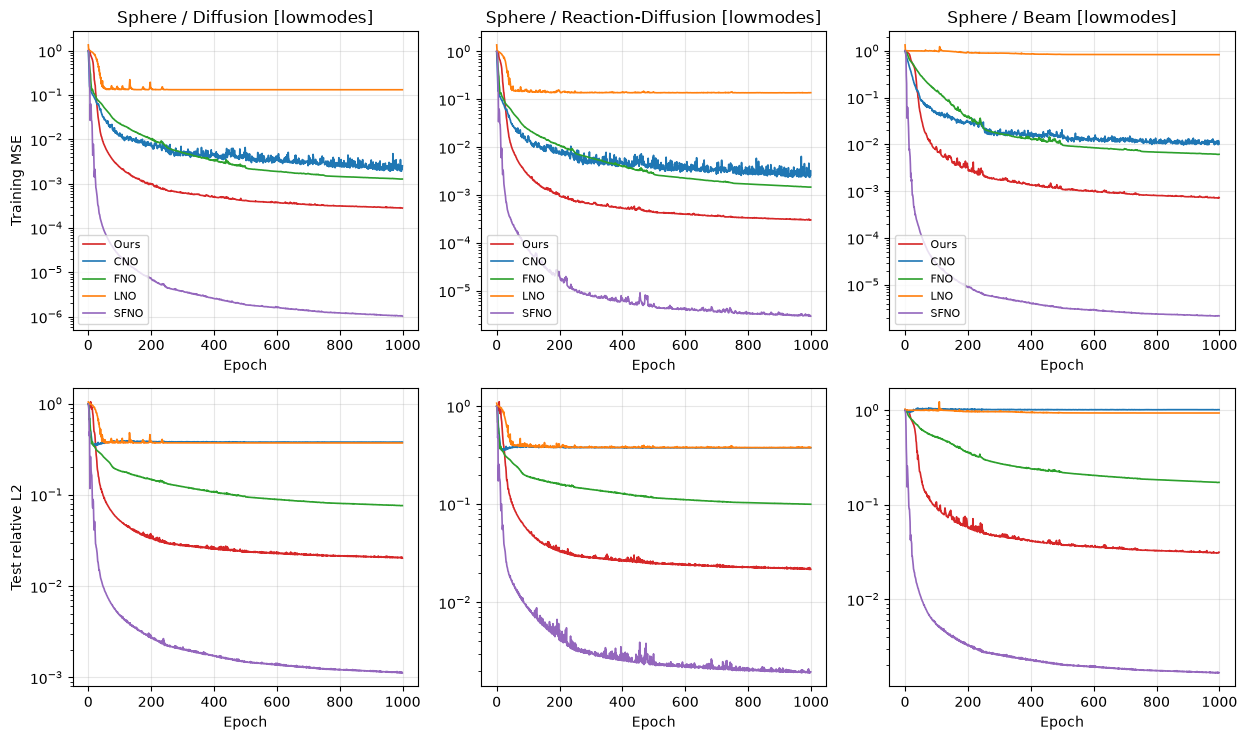

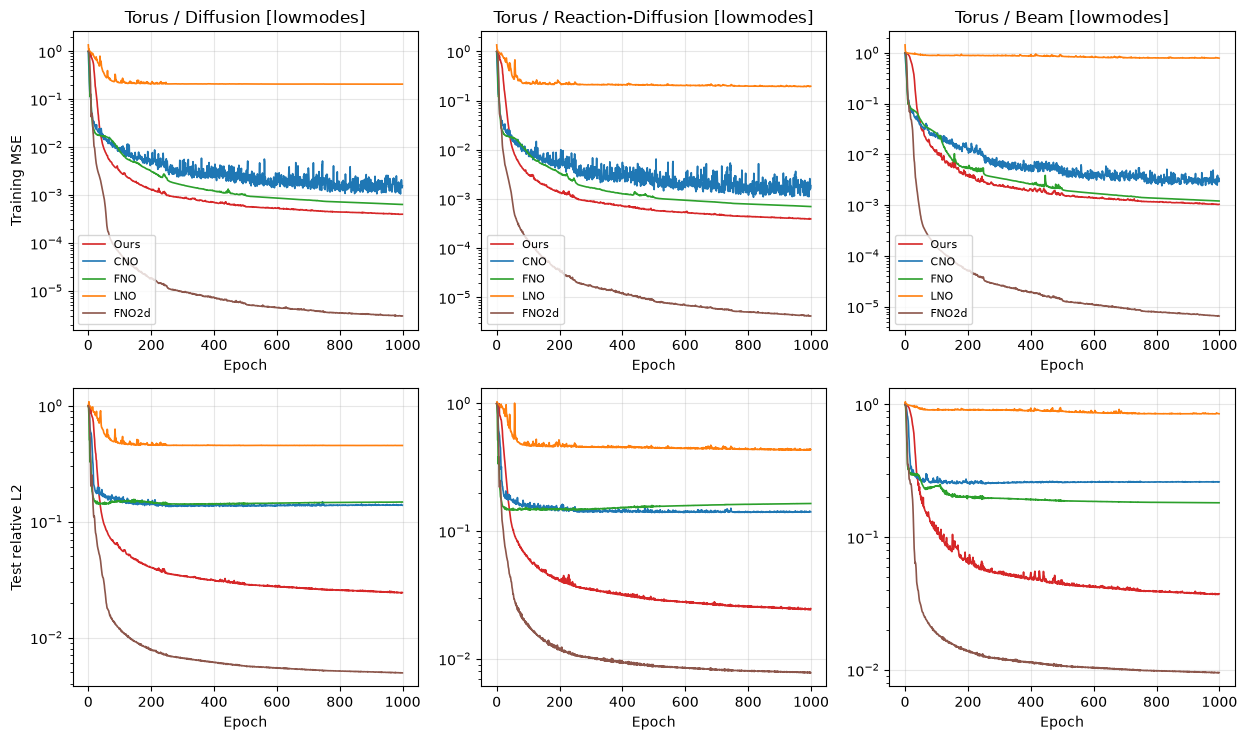

In [14]:
colors = {"Ours": "#d62728", "CNO": "#1f77b4", "FNO": "#2ca02c",
          "LNO": "#ff7f0e", "SFNO": "#9467bd", "FNO2d": "#8c564b"}

systems = ["Diffusion", "Reaction-Diffusion", "Beam"]

for domain_name in DOMAIN_NAMES:
    fig, axes = plt.subplots(2, len(systems), figsize=(4.2 * len(systems), 7.5))

    for column, system in enumerate(systems):
        ax_loss, ax_error = axes[0, column], axes[1, column]

        for model_name, history in histories[(domain_name, system)].items():
            ax_loss.semilogy(history["train_loss"], label=model_name,
                             color=colors[model_name], linewidth=1.2)
            ax_error.semilogy(history["test_error"], label=model_name,
                              color=colors[model_name], linewidth=1.2)

        ax_loss.set_title(f"{domain_name} / {system} [{IC_TYPE}]")
        ax_loss.set_xlabel("Epoch")
        ax_error.set_xlabel("Epoch")
        if column == 0:
            ax_loss.set_ylabel("Training MSE")
            ax_error.set_ylabel("Test relative L2")
        ax_loss.legend(fontsize=8)
        ax_loss.grid(alpha=0.3)
        ax_error.grid(alpha=0.3)

    plt.tight_layout()
    fig.savefig(f"results/loss_curves_v2_{IC_TYPE}_{domain_name}_{run_id}.png", dpi=150)
    plt.show()

## Example predictions on the surface

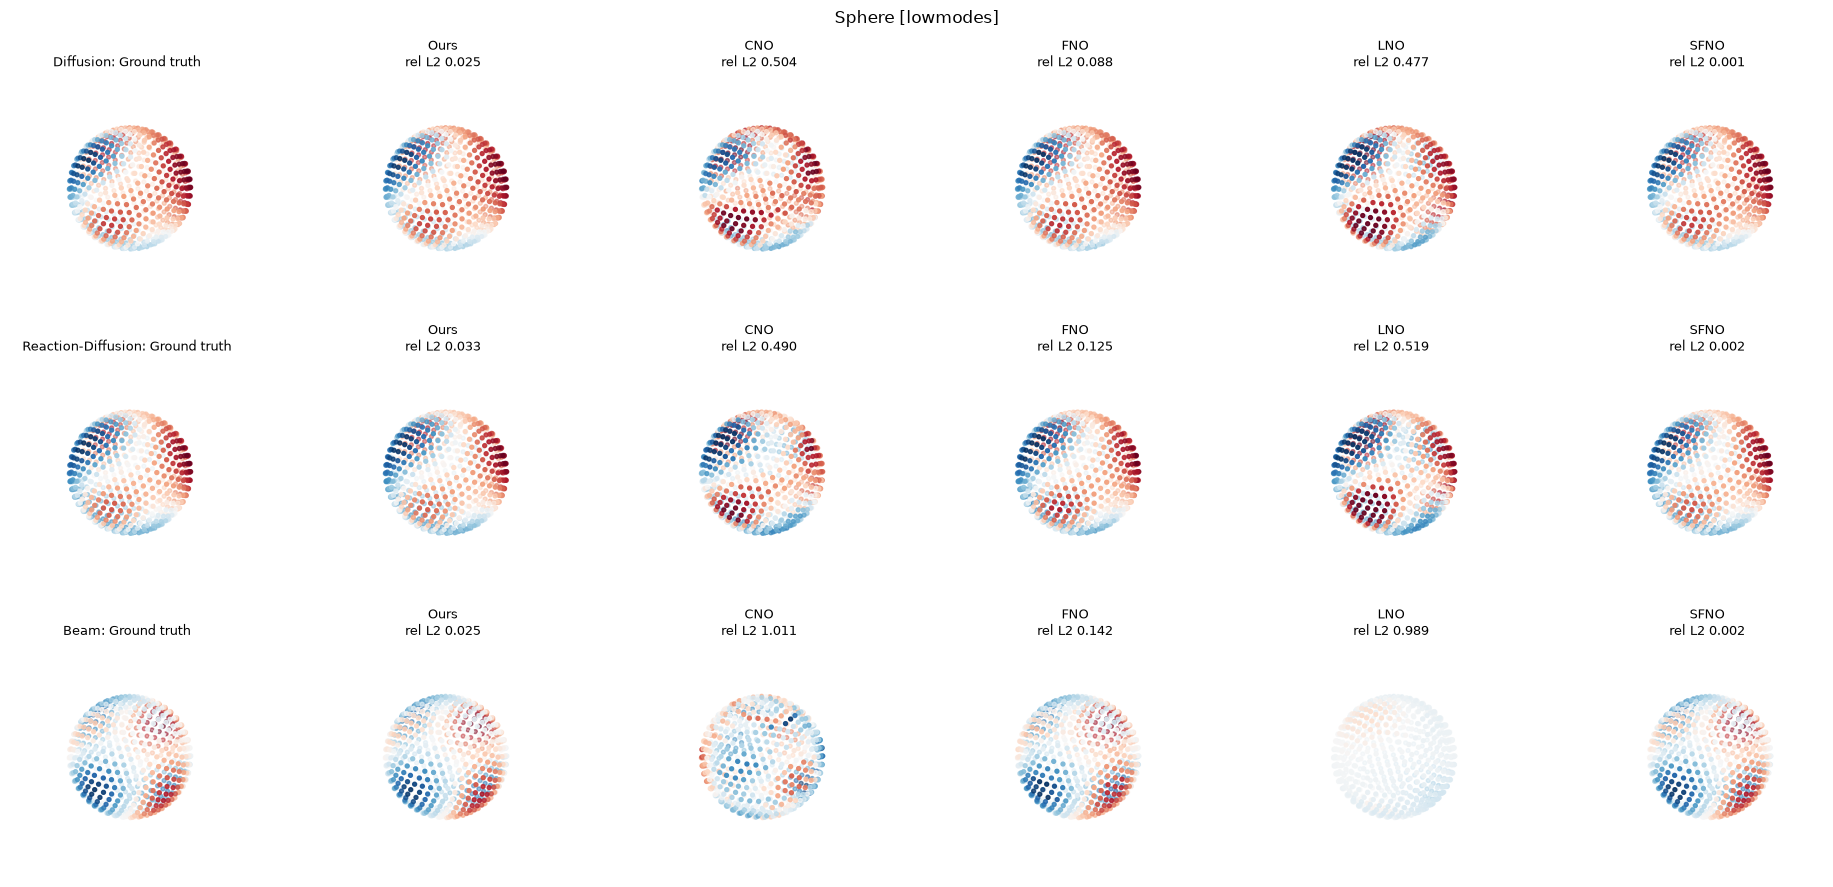

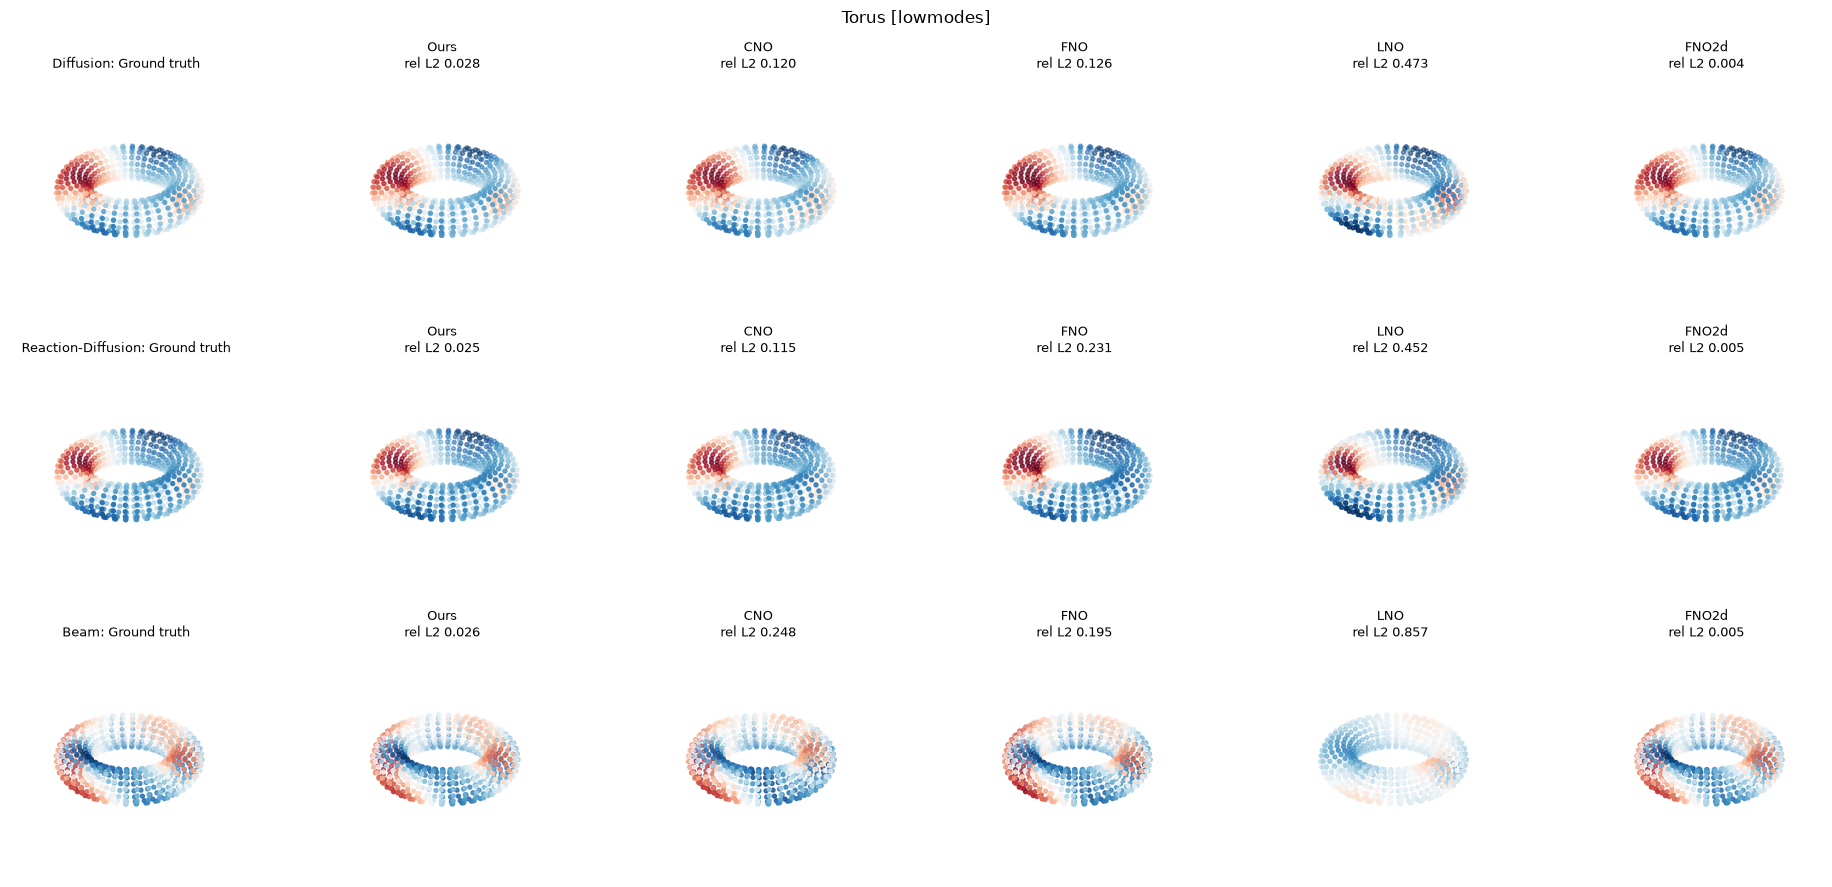

In [15]:
sample = 0

for domain_name in DOMAIN_NAMES:
    points = domains[domain_name].points
    names = [m for m in model_names if m in trained_models[(domain_name, systems[0])]]
    columns = ["Ground truth"] + names
    fig = plt.figure(figsize=(3.2 * len(columns), 3.0 * len(systems)))

    for row, system in enumerate(systems):
        X, Y = datasets[(domain_name, system)]
        fields = {"Ground truth": Y[N_TRAIN + sample, :, 0].numpy()}

        for model_name in names:
            model = trained_models[(domain_name, system)][model_name]
            model.eval()
            with torch.no_grad():
                fields[model_name] = model(
                    X[N_TRAIN + sample:N_TRAIN + sample + 1].to(device)
                )[0, :, 0].cpu().numpy()

        vmin, vmax = fields["Ground truth"].min(), fields["Ground truth"].max()

        for column, name in enumerate(columns):
            ax = fig.add_subplot(len(systems), len(columns),
                                 row * len(columns) + column + 1, projection="3d")
            ax.scatter(points[:, 0], points[:, 1], points[:, 2],
                       c=fields[name], cmap="RdBu_r", vmin=vmin, vmax=vmax, s=8)
            ax.set_box_aspect(np.ptp(points, axis=0))
            ax.set_axis_off()
            error = "" if name == "Ground truth" else (
                f"\nrel L2 {np.linalg.norm(fields[name] - fields['Ground truth']) / np.linalg.norm(fields['Ground truth']):.3f}"
            )
            ax.set_title(f"{system}: {name}{error}" if column == 0 else f"{name}{error}",
                         fontsize=9)

    fig.suptitle(f"{domain_name} [{IC_TYPE}]")
    plt.tight_layout()
    fig.savefig(f"results/predictions_v2_{IC_TYPE}_{domain_name}_{run_id}.png", dpi=150)
    plt.show()

## Reading the results

- **Ours vs SFNO / FNO2d** is the fair comparison: all three see the true
  geometry. FNO2d's grid is the torus mesh itself; SFNO pays the printed
  "SFNO floor" for moving between the mesh and its grid.
- **`noise` vs `lowmodes`**: compare our error against the printed
  "outside 96 modes" fraction of `u(T)`. If they are close, our error is
  dominated by basis truncation (raise `N_MODES`); if ours is much larger,
  the limit is what the model learns, not what it can represent.
- **`lowmodes` reproducibility**: the data use the same code and seed as
  `benchmark_manifolds.ipynb`, but ARPACK may return a different basis inside
  each degenerate eigenspace (e.g. the l = 1, 2, 3 multiplets of the sphere),
  which changes the individual samples, not their distribution. Including
  `FNO` in `MODELS` gives an anchor: if its errors match the previous run,
  the datasets are the same.